### Importing necessary libraries

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
import hvplot.pandas
import plotly.express as px


import warnings
import gc
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
%matplotlib inline

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc,
    #plot_confusion_matrix, 
    #plot_roc_curve
)
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

from sklearn.ensemble import RandomForestClassifier
#from xgboost import XGBClassifier

print("Libraries importes successfully.")

Libraries importes successfully.


### Loading the entire data

In [2]:
start_df = pd.read_csv('loan_data.csv', low_memory=False)

Working on a copy of the dataframe so that I do not have to re-read the entire dataset again in order to save memory.

In [3]:
df = start_df.copy(deep=True)
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,NaN,NaN,2500,2500,2500.0,36 months,13.56,84.92,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,30000,30000,30000.0,60 months,18.94,777.23,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,5000,5000,5000.0,36 months,17.97,180.69,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,4000,4000,4000.0,36 months,18.94,146.51,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,30000,30000,30000.0,60 months,16.14,731.78,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


### Checking the shape of the data

In [4]:
print(df.shape)

(2260668, 145)


In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2260668 entries, 0 to 2260667
Columns: 145 entries, id to settlement_term
dtypes: float64(105), int64(4), str(36)
memory usage: 2.8 GB
None


In [6]:
print(df.isnull().sum())

id                       2260668
member_id                2260668
loan_amnt                      0
funded_amnt                    0
funded_amnt_inv                0
                          ...   
settlement_status        2227612
settlement_date          2227612
settlement_amount        2227612
settlement_percentage    2227612
settlement_term          2227612
Length: 145, dtype: int64


### Understanding the data

First, let's check the description of the various column fields in the dataset

In [7]:
print(df.columns.tolist())

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_i

In [8]:
df_description = pd.read_excel('LCDataDictionary.xlsx').dropna()
df_description.style.set_properties(subset=['Description'], **{'width': '1000px'})

,LoanStatNew,Description
0,acc_now_delinq,The number of accounts on which the borrower is now delinquent.
1,acc_open_past_24mths,Number of trades opened in past 24 months.
2,addr_state,The state provided by the borrower in the loan application
3,all_util,Balance to credit limit on all trades
4,annual_inc,The self-reported annual income provided by the borrower during registration.
5,annual_inc_joint,The combined self-reported annual income provided by the co-borrowers during registration
6,application_type,Indicates whether the loan is an individual application or a joint application with two co-borrowers
7,avg_cur_bal,Average current balance of all accounts
8,bc_open_to_buy,Total open to buy on revolving bankcards.
9,bc_util,Ratio of total current balance to high credit/credit limit for all bankcard accounts.


looking at the data we can clearly detect some of the important variables such as -- loan_amnt, int_rate, term, installment, grade, sub_grade, emp_length, home_ownership, annual_inc, loan_status, dti, delinq_2yrs, pub_rec, revol_util etc 

In [9]:
for column in df.columns:
    if df[column].isna().sum() != 0:
        missing = df[column].isna().sum()
        portion = (missing / df.shape[0]) * 100
        print(f"'{column}': number of missing values '{missing}' ==> '{portion:.3f}%'")

'id': number of missing values '2260668' ==> '100.000%'
'member_id': number of missing values '2260668' ==> '100.000%'
'emp_title': number of missing values '166969' ==> '7.386%'
'emp_length': number of missing values '146907' ==> '6.498%'
'annual_inc': number of missing values '4' ==> '0.000%'
'url': number of missing values '2260668' ==> '100.000%'
'desc': number of missing values '2134603' ==> '94.424%'
'title': number of missing values '23326' ==> '1.032%'
'zip_code': number of missing values '1' ==> '0.000%'
'dti': number of missing values '1711' ==> '0.076%'
'delinq_2yrs': number of missing values '29' ==> '0.001%'
'earliest_cr_line': number of missing values '29' ==> '0.001%'
'inq_last_6mths': number of missing values '30' ==> '0.001%'
'mths_since_last_delinq': number of missing values '1158502' ==> '51.246%'
'mths_since_last_record': number of missing values '1901512' ==> '84.113%'
'open_acc': number of missing values '29' ==> '0.001%'
'pub_rec': number of missing values '29' =

As there are a lot of columns with more than 50% of rows with missing values, we can drop those.

In [10]:
missing_percentage = df.isnull().mean() * 100

columns_to_drop = missing_percentage[missing_percentage > 30].index

df = df.drop(columns=columns_to_drop)

In [11]:
print(df.shape)

(2260668, 87)


In [12]:
for column in df.columns:
    if df[column].isna().sum() != 0:
        missing = df[column].isna().sum()
        portion = (missing / df.shape[0]) * 100
        print(f"'{column}': number of missing values '{missing}' ==> '{portion:.3f}%'")

'emp_title': number of missing values '166969' ==> '7.386%'
'emp_length': number of missing values '146907' ==> '6.498%'
'annual_inc': number of missing values '4' ==> '0.000%'
'title': number of missing values '23326' ==> '1.032%'
'zip_code': number of missing values '1' ==> '0.000%'
'dti': number of missing values '1711' ==> '0.076%'
'delinq_2yrs': number of missing values '29' ==> '0.001%'
'earliest_cr_line': number of missing values '29' ==> '0.001%'
'inq_last_6mths': number of missing values '30' ==> '0.001%'
'open_acc': number of missing values '29' ==> '0.001%'
'pub_rec': number of missing values '29' ==> '0.001%'
'revol_util': number of missing values '1802' ==> '0.080%'
'total_acc': number of missing values '29' ==> '0.001%'
'last_pymnt_d': number of missing values '2426' ==> '0.107%'
'last_credit_pull_d': number of missing values '73' ==> '0.003%'
'collections_12_mths_ex_med': number of missing values '145' ==> '0.006%'
'acc_now_delinq': number of missing values '29' ==> '0.0

In [13]:
print(df.columns.tolist())

['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', 'delinq_amnt', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_rec

### Checking the status of loans

In [14]:
df["loan_status"].value_counts(dropna=False)

loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31
Name: count, dtype: int64

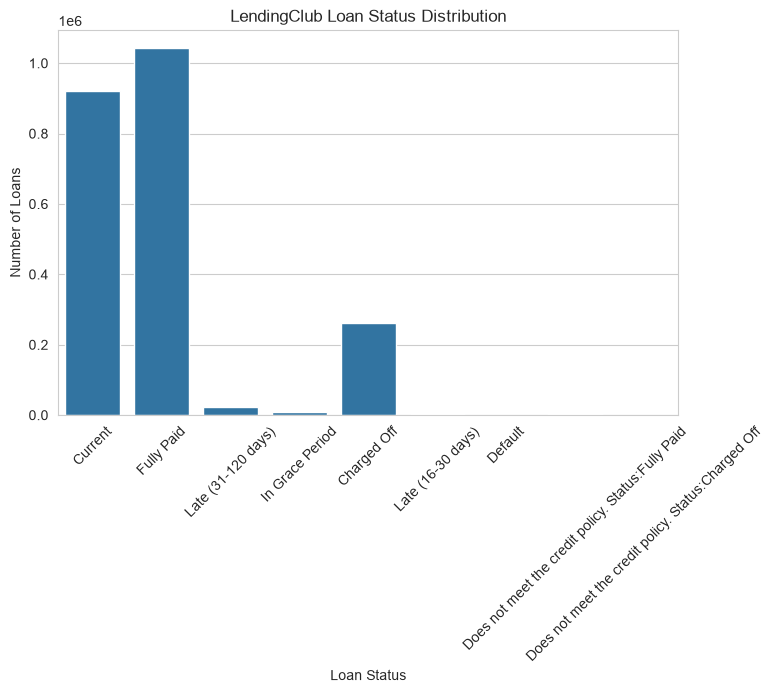

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="loan_status"
)

plt.title("LendingClub Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")

plt.xticks(rotation=45)

plt.show()

In [16]:
# making the graph again (interactive)
df['loan_status'].value_counts().hvplot.bar(
    title="Loan Status Counts", xlabel='Loan Status', ylabel='Count', 
    width=600, height=300
)

:Bars   [loan_status]   (count)

Since we cannot work with currently ongoing loans, we are only keeping the loans that are either fully paid off or have been defaulted and excluding the active loans

In [17]:
# Filter completed loans (exclude active 'Current' loans)
df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off', 'Default'])].copy()
print(df.head())

     loan_amnt  funded_amnt  funded_amnt_inv        term  int_rate  \
100      30000        30000          30000.0   36 months     22.35   
152      40000        40000          40000.0   60 months     16.14   
170      20000        20000          20000.0   36 months      7.56   
186       4500         4500           4500.0   36 months     11.31   
215       8425         8425           8425.0   36 months     27.27   

     installment grade sub_grade                             emp_title  \
100      1151.16     D        D5                           Supervisor    
152       975.71     C        C4  Assistant to the Treasurer (Payroll)   
170       622.68     A        A3                               Teacher   
186       147.99     B        B3                 Accounts Examiner III   
215       345.18     E        E5       Senior Director Risk Management   

    emp_length  ... percent_bc_gt_75  pub_rec_bankruptcies tax_liens  \
100    5 years  ...             33.3                   1.0    

In [18]:
print(df["loan_status"].value_counts(dropna=False))
print(f"\nremaining data", df.shape)

loan_status
Fully Paid     1041952
Charged Off     261655
Default             31
Name: count, dtype: int64

remaining data (1303638, 87)


Loan default is our target variable with values 1 for "Charged off" or "Default" and 0 for "Fully paid"

In [19]:
df['target'] = np.where(df['loan_status'].isin(['Charged Off', 'Default']), 1, 0)

Making the heatmap of correlation matrix of only the numerical data

In [20]:
import hvplot.pandas

# Select only numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
corr = numeric_df.corr()

# Convert correlation matrix to long format
corr_long = corr.stack().reset_index()

# Rename columns
corr_long.columns = ["variable_1", "variable_2", "correlation"]

# Interactive heatmap
corr_long.hvplot.heatmap(
    x="variable_1",
    y="variable_2",
    C="correlation",
    cmap="RdBu_r",
    clim=(-1, 1),
    width=1000,
    height=1000,
    title="Interactive Correlation Matrix"
).opts(
    colorbar=True,
    tools=["hover"]
)

:HeatMap   [variable_1,variable_2]   (correlation)

Still here so many columns are unimportant here, so we will create another Correlation matrix heatmap but only including the columns with numerical that logically make sense.

In [21]:
selected_cols = [
    "loan_amnt",
    "int_rate",
    "installment",
    "annual_inc",
    "dti",
    "total_bc_limit",
    "revol_bal",
    "revol_util",
    "open_acc",
    "total_acc",
    "delinq_2yrs"
]

# Select the columns
selected_df = df[selected_cols]

# Calculate correlations
corr = selected_df.corr()

# Convert correlation matrix to long format
corr_long = corr.stack().reset_index()

corr_long.columns = [
    "variable_1",
    "variable_2",
    "correlation"
]

# Interactive heatmap
corr_long.hvplot.heatmap(
    x="variable_1",
    y="variable_2",
    C="correlation",
    cmap="RdBu_r",
    clim=(-1, 1),
    width=900,
    height=900,
    title="Credit Risk Variable Correlation Matrix"
).opts(
    colorbar=True,
    tools=["hover"]
)

:HeatMap   [variable_1,variable_2]   (correlation)

Most of the relationships we see here logically make perfect sense, such as installment and loan amount and total_bank_credit_limit. Someone who has high income will have high bank credit limit and some who took a large amount of loan will have a high installment amount.

In [22]:
installment = df.hvplot.hist(
    y='installment', by='loan_status', subplots=False, 
    width=450, height=500, bins=50, alpha=0.4, 
    title="Installment by Loan Status", 
    xlabel='Installment', ylabel='Counts', legend='top'
)

loan_amnt = df.hvplot.hist(
    y='loan_amnt', by='loan_status', subplots=False, 
    width=450, height=500, bins=30, alpha=0.4, 
    title="Loan Amount by Loan Status", 
    xlabel='Loan Amount', ylabel='Counts', legend='top'
)

installment + loan_amnt

:Layout
   .NdOverlay.I  :NdOverlay   [loan_status]
      :Histogram   [installment]   (Count)
   .NdOverlay.II :NdOverlay   [loan_status]
      :Histogram   [loan_amnt]   (Count)

In [23]:
plot_df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
]

plot_df.hvplot.hist(
    y="installment",
    by="loan_status",
    subplots=False,
    bins=40,
    alpha=0.5,
    width=700,
    height=400,
    title="Monthly Installment: Fully Paid vs Charged Off",
    xlabel="Monthly installment ($)",
    ylabel="Number of loans",
    legend="top"
)

:NdOverlay   [loan_status]
   :Histogram   [installment]   (Count)

In [24]:
loan_amnt_box = df.hvplot.box(
    y='loan_amnt', subplots=True, by='loan_status', width=500, height=350, 
    title="Loan Status by Loan Amount ", xlabel='Loan Status', ylabel='Loan Amount'
)

installment_box = df.hvplot.box(
    y='installment', subplots=True, by='loan_status', width=500, height=350, 
    title="Loan Status by Installment", xlabel='Loan Status', ylabel='Installment'
)

loan_amnt_box + installment_box

:Layout
   .BoxWhisker.I  :BoxWhisker   [loan_status]   (loan_amnt)
   .BoxWhisker.II :BoxWhisker   [loan_status]   (installment)

In [25]:
df.groupby(by='loan_status')['loan_amnt'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_status,,,,,,,,
Charged Off,261655.0,15548.979381,8797.539356,900.0,9000.0,14350.0,20400.0,40000.0
Default,31.0,15800.000000,10009.210342,1000.0,7412.5,16000.0,22500.0,40000.0
Fully Paid,1041952.0,14132.493699,8651.520017,500.0,7500.0,12000.0,20000.0,40000.0


In [26]:
print(f"GRADE unique: {df.grade.unique()}")
print(f"SUB_GRADE unique: {df.sub_grade.unique()}")

GRADE unique: <ArrowStringArray>
['D', 'C', 'A', 'B', 'E', 'G', 'F']
Length: 7, dtype: str
SUB_GRADE unique: <ArrowStringArray>
['D5', 'C4', 'A3', 'B3', 'E5', 'D1', 'C1', 'A4', 'E1', 'B5', 'E4', 'B1', 'D2',
 'B4', 'B2', 'C3', 'A5', 'C2', 'A2', 'C5', 'D3', 'D4', 'E2', 'A1', 'E3', 'G2',
 'F1', 'G4', 'F2', 'F4', 'F3', 'F5', 'G1', 'G5', 'G3']
Length: 35, dtype: str


In [27]:
fully_paid = df.loc[df['loan_status']=='Fully Paid', 'grade'].value_counts().hvplot.bar(label= "Fully Paid", color = "orangered") 
charged_off = df.loc[df['loan_status']=='Charged Off', 'grade'].value_counts().hvplot.bar(label="Charged Off", color = "steelblue") 

(fully_paid * charged_off).opts(
    title="Loan Status by Grade", xlabel='Grades', ylabel='Number of Loans',
    width=500, height=450, legend_cols=2, legend_position='top_right', xrotation=90
)

:Overlay
   .Bars.Fully_Paid  :Bars   [grade]   (count)
   .Bars.Charged_Off :Bars   [grade]   (count)

In [57]:
corr = df.select_dtypes(include="number").corr()

corr["target"].drop("target").sort_values().hvplot.barh(
    width=700,
    height=500,
    title="Correlation with Loan Default",
    xlabel="Correlation",
    ylabel="Numeric Features"
)

:Bars   [index]   (target)

### Checking different columns and Keeping only the relevant variables

### Categorical Variables (using Dummy variable)

In [28]:
print(df.select_dtypes(include=["object", "string"]).columns.tolist())

['term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'purpose', 'title', 'zip_code', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'last_pymnt_d', 'last_credit_pull_d', 'application_type', 'hardship_flag', 'disbursement_method', 'debt_settlement_flag']


##### term

In [29]:
df.term.unique()

<ArrowStringArray>
[' 36 months', ' 60 months']
Length: 2, dtype: str

In [30]:
term_values = {' 36 months': 36, ' 60 months': 60}
df['term'] = df.term.map(term_values)

In [31]:
df.term.unique()

array([36, 60])

##### grade & sub_grade
We know that grade is just a sub feature of sub_grade, So we are goinig to drop it.

In [32]:
df.drop('grade', axis=1, inplace=True)

In [33]:
dummies = ['sub_grade', 'verification_status', 'purpose', 'initial_list_status', 
           'application_type', 'home_ownership']
df = pd.get_dummies(df, columns=dummies, drop_first=True)

##### emp_length

In [34]:
df.emp_length.unique()

<ArrowStringArray>
[  '5 years',  '< 1 year', '10+ years',   '3 years',   '4 years',    '1 year',
   '8 years',         nan,   '2 years',   '6 years',   '9 years',   '7 years']
Length: 12, dtype: str

In [35]:
for year in df.emp_length.unique():
    print(f"{year} years in this position:")
    print(f"{df[df.emp_length == year].loan_status.value_counts(normalize=True)}")
    print('==========================================')

5 years years in this position:
loan_status
Fully Paid     0.803033
Charged Off    0.196967
Name: proportion, dtype: float64
< 1 year years in this position:
loan_status
Fully Paid     0.793194
Charged Off    0.206787
Default        0.000019
Name: proportion, dtype: float64
10+ years years in this position:
loan_status
Fully Paid     0.811148
Charged Off    0.188838
Default        0.000014
Name: proportion, dtype: float64
3 years years in this position:
loan_status
Fully Paid     0.799077
Charged Off    0.200885
Default        0.000038
Name: proportion, dtype: float64
4 years years in this position:
loan_status
Fully Paid     0.801033
Charged Off    0.198916
Default        0.000051
Name: proportion, dtype: float64
1 year years in this position:
loan_status
Fully Paid     0.793506
Charged Off    0.206482
Default        0.000012
Name: proportion, dtype: float64
8 years years in this position:
loan_status
Fully Paid     0.799347
Charged Off    0.200619
Default        0.000034
Name: propor

Charge off rates are extremely similar across all employment lengths. So we are going to drop the emp_length column.

In [36]:
df.drop('emp_length', axis=1, inplace=True)

##### emp_title

In [37]:
df.emp_title.nunique()

371436

Realistically there are too many unique job titles to try to convert this to a dummy variable feature. Let's remove that emp_title column.

##### Zip code
We are going to feature engineer a zip code column from the address in the data set. Create a column called 'zip_code' that extracts the zip code from the address column.

In [38]:
df["zip_code"].head(25)

100     917xx
152     456xx
170     982xx
186     786xx
215     020xx
269     981xx
271     750xx
296     194xx
369     760xx
379     481xx
402     435xx
412     836xx
445     920xx
510     775xx
576     850xx
646     145xx
765     712xx
800     028xx
829     605xx
835     370xx
873     898xx
930     600xx
1066    750xx
1104    551xx
1106    871xx
Name: zip_code, dtype: str

In [39]:
df.zip_code.nunique()

943

too  many uniquie values to incorporate as a dummy

##### addr_state

In [40]:
df.addr_state.nunique()

51

we have 51 different, including this much dummies is unnecessary so we are dropping it

In [41]:
df.drop('addr_state', axis=1, inplace=True)

##### issue_d

This would be data leakage, we wouldn't know beforehand whether or not a loan would be issued when using our model, so in theory we wouldn't have an issue_date, drop this feature.

In [42]:
df.drop('issue_d', axis=1, inplace=True)

Checking all the columns one last time

In [43]:
print(df.columns.tolist())

['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'emp_title', 'annual_inc', 'loan_status', 'pymnt_plan', 'title', 'zip_code', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'policy_code', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', 'delinq_amnt', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'n

### Prepping the data for making the model

In [46]:
features = [
    'loan_amnt',
    'term',
    'int_rate',
    'installment',
    'annual_inc',
    'dti',
    'delinq_2yrs',
    'inq_last_6mths',
    'open_acc',
    'pub_rec',
    'revol_bal',
    'revol_util',
    'total_acc',
    'collections_12_mths_ex_med',
    'acc_now_delinq',
    'tot_coll_amt',
    'tot_cur_bal',
    'total_rev_hi_lim',
    'mort_acc',
    'pub_rec_bankruptcies'
]

dummy_cols = [
    col for col in df.columns
    if col.startswith((
        'sub_grade_',
        'verification_status_',
        'purpose_',
        'initial_list_status_',
        'application_type_',
        'home_ownership_'
    ))
]

features = features + dummy_cols

In [47]:
X = df[features]

In [48]:
y = df['target']

In [49]:
print(X.shape)
print(y.shape)

(1303638, 76)
(1303638,)


In [50]:
X.isnull().sum().sort_values(ascending=False).head(20)

tot_cur_bal                   67527
total_rev_hi_lim              67527
tot_coll_amt                  67527
mort_acc                      47281
revol_util                      810
pub_rec_bankruptcies            697
dti                             312
collections_12_mths_ex_med       56
inq_last_6mths                    1
int_rate                          0
installment                       0
loan_amnt                         0
revol_bal                         0
pub_rec                           0
open_acc                          0
delinq_2yrs                       0
annual_inc                        0
term                              0
acc_now_delinq                    0
total_acc                         0
dtype: int64

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [52]:
# Find numeric columns
numeric_cols = X_train.select_dtypes(include="number").columns

# Calculate medians using TRAINING data only
train_medians = X_train[numeric_cols].median()

# Fill missing values
X_train[numeric_cols] = X_train[numeric_cols].fillna(train_medians)
X_test[numeric_cols] = X_test[numeric_cols].fillna(train_medians)

In [53]:
print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [54]:
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

### Now building the Models

In [55]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Logistitic Model

In [56]:
log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [58]:
y_pred_log = log_model.predict(X_test_scaled)

y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

y_pred_log gives the predicted class, as in whether the loans are in Default/Charged off or Fully paid. eg, 0 1 0 0 1
y_prob_log gives the 'Probability of Default'. eg, 0.12, 0.73, 0.28, 0.09, 0.81

In [59]:
print("LOGISTIC REGRESSION")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nROC-AUC:")
print(roc_auc_score(y_test, y_prob_log))

LOGISTIC REGRESSION

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.63      0.73    208391
           1       0.31      0.68      0.43     52337

    accuracy                           0.64    260728
   macro avg       0.60      0.65      0.58    260728
weighted avg       0.77      0.64      0.67    260728


Confusion Matrix:
[[130520  77871]
 [ 16944  35393]]

ROC-AUC:
0.7090611329980528


130,520 True Negatives: good loans correctly classified as good.
77,871 False Positives: good loans incorrectly classified as default.
16,944 False Negatives: defaulting loans incorrectly classified as good.
35,393 True Positives: defaulting loans correctly identified.

Recall for defaults = 68%
This means your model successfully detected about 68% of the loans that actually defaulted.
So out of every 100 actual defaults, your model identifies roughly 68 and misses roughly 32.

But precision for defaults is only 31%
your model is being fairly aggressive about flagging borrowers as risky.
A major reason is this:
class_weight="balanced"
You told Logistic Regression to place more weight on the minority class — defaults.
That helps the model catch more defaults, but there's a trade-off:
Higher default recall → more good borrowers incorrectly flagged as risky.
That's why you have 77,871 false positives.

Your ROC-AUC = 0.709
ROC-AUC measures how well the model ranks default risk, independent of choosing one specific classification threshold.

An intuitive interpretation is:
If we randomly select one defaulting borrower and one non-defaulting borrower, your model has about a 70.9% probability of assigning the defaulting borrower the higher predicted risk score.


In [60]:
auc_log = roc_auc_score(y_test, y_prob_log)

### Logistic Regression without Balancing

In [72]:
log_model_unbalanced = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model_unbalanced.fit(X_train_scaled, y_train)

y_pred_unbalanced = log_model_unbalanced.predict(X_test_scaled)
y_prob_unbalanced = log_model_unbalanced.predict_proba(X_test_scaled)[:, 1]

print("LOGISTIC REGRESSION w/o Balancing")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_unbalanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_unbalanced))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_unbalanced)
)

LOGISTIC REGRESSION w/o Balancing

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.99      0.89    208391
           1       0.57      0.06      0.11     52337

    accuracy                           0.80    260728
   macro avg       0.69      0.52      0.50    260728
weighted avg       0.76      0.80      0.73    260728


Confusion Matrix:
[[205963   2428]
 [ 49167   3170]]
ROC-AUC: 0.7088980315216935


### Random Forest

In [67]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [68]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [69]:
print("RANDOM FOREST")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nROC-AUC:")
print(roc_auc_score(y_test, y_prob_rf))

RANDOM FOREST

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.63      0.74    208391
           1       0.31      0.67      0.43     52337

    accuracy                           0.64    260728
   macro avg       0.60      0.65      0.58    260728
weighted avg       0.77      0.64      0.68    260728


Confusion Matrix:
[[132050  76341]
 [ 17233  35104]]

ROC-AUC:
0.7108226037927327


In [70]:
auc_rf = roc_auc_score(y_test, y_prob_rf)

### Compare the 2 models

In [65]:
print(f"Logistic Regression ROC-AUC: {auc_log:.4f}")
print(f"Random Forest ROC-AUC:       {auc_rf:.4f}")

Logistic Regression ROC-AUC: 0.7091
Random Forest ROC-AUC:       0.7107


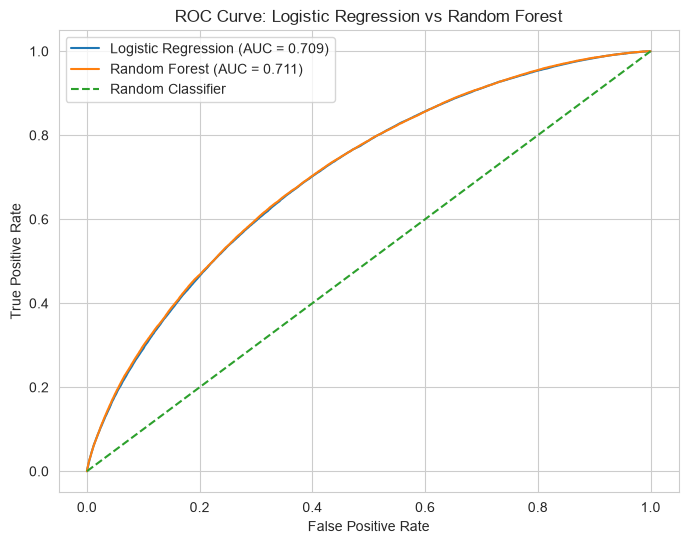

In [66]:
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(fpr_log, tpr_log,
         label=f"Logistic Regression (AUC = {auc_log:.3f})")

plt.plot(fpr_rf, tpr_rf,
         label=f"Random Forest (AUC = {auc_rf:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Logistic Regression vs Random Forest")
plt.legend()

plt.show()

### Gini of both the models

In [73]:
gini_log = 2 * auc_log - 1
gini_rf = 2 * auc_rf - 1

print(f"Logistic Regression Gini: {gini_log:.4f}")
print(f"Random Forest Gini: {gini_rf:.4f}")

Logistic Regression Gini: 0.4181
Random Forest Gini: 0.4216


### PD -- Probability of Default

Probability of Default from Logistic model is  **y_prob_log**

Probability of Default from the Random Forest model is **y_prob_rf**

### LGD -- Loss Given Default

From the above graph we can see that a higher income tends to be negatively correlated with default, where as a higher **Installment Amount** and a higher **Interest Rate**, **Debt-to-Income** ratio tend to be positively correlated with **Default**.

In [76]:
defaulted = df[df["target"] == 1].copy()

defaulted["recovery_rate"] = (
    defaulted["recoveries"] / defaulted["funded_amnt"]
)

defaulted["recovery_rate"] = defaulted["recovery_rate"].clip(0, 1)

defaulted["LGD"] = 1 - defaulted["recovery_rate"]

In [77]:
defaulted[[
    "funded_amnt",
    "recoveries",
    "recovery_rate",
    "LGD"
]].head()

,funded_amnt,recoveries,recovery_rate,LGD
5040,8000,0.0,0.0,1.0
25963,6000,0.0,0.0,1.0
41393,10000,0.0,0.0,1.0
55148,10000,0.0,0.0,1.0
58105,35000,0.0,0.0,1.0


In [78]:
average_lgd = defaulted["LGD"].mean()

print(f"Average LGD: {average_lgd:.2%}")

Average LGD: 92.67%


Tthis is a simplified LGD proxy based on observed recoveries.

### EAD -- Exposure at Default

EAD: Funded loan amount was used as a simplified proxy for exposure at default.

EAD ~ Funded Amount

In [79]:
df["EAD"] = df["funded_amnt"]

### LGD - Loss Given Default
LGD: Estimated from observed recoveries on defaulted/charged-off loans, with LGD calculated as one minus the recovery rate.

Recovery Rate = Recoveries/ EAD

LGD = 1- Recovery Rate

In [80]:
defaulted = df[df["target"] == 1].copy()

defaulted["recovery_rate"] = (
    defaulted["recoveries"] / defaulted["funded_amnt"]
)

defaulted["recovery_rate"] = defaulted["recovery_rate"].clip(0, 1)

defaulted["LGD"] = 1 - defaulted["recovery_rate"]

In [81]:
defaulted[[
    "funded_amnt",
    "recoveries",
    "recovery_rate",
    "LGD"
]].head()

,funded_amnt,recoveries,recovery_rate,LGD
5040,8000,0.0,0.0,1.0
25963,6000,0.0,0.0,1.0
41393,10000,0.0,0.0,1.0
55148,10000,0.0,0.0,1.0
58105,35000,0.0,0.0,1.0


In [95]:
average_lgd = defaulted["LGD"].mean()

print(f"**Average LGD**: {average_lgd:.2%}")

**Average LGD**: 92.67%


### EL -- Expected Loss 
#### EL = PD x LGD x EAD

In [83]:
results = df.loc[X_test.index].copy()

In [96]:
results["PD_Logistic"] = y_prob_log
results["PD_RF"] = y_prob_rf

In [85]:
results["EAD"] = results["funded_amnt"]

In [86]:
results["LGD"] = average_lgd

In [97]:
results["EL_Logistic"] = (
    results["PD_Logistic"] *
    results["LGD"] *
    results["EAD"]
)

results["EL_RF"] = (
    results["PD_RF"] *
    results["LGD"] *
    results["EAD"]
)

In [98]:
results[[
    "PD_Logistic",
    "PD_RF",
    "LGD",
    "EAD",
    "EL_Logistic",
    "EL_RF"
]].head(10)

,PD_Logistic,PD_RF,LGD,EAD,EL_Logistic,EL_RF
836676,0.354805,0.323182,0.92674,5000,1644.061965,1497.527277
1809273,0.484131,0.487672,0.92674,35000,15703.208799,15818.065462
832877,0.666126,0.670542,0.92674,24000,14815.820367,14914.037662
1641017,0.275727,0.273946,0.92674,15000,3832.901793,3808.145841
1981375,0.328930,0.407388,0.92674,7000,2133.825763,2642.796447
1720111,0.558066,0.570954,0.92674,12175,6296.687579,6442.107994
1329802,0.416852,0.471736,0.92674,18000,6953.638899,7869.172911
235765,0.269575,0.309991,0.92674,5000,1249.131262,1436.403935
2106405,0.748557,0.664376,0.92674,12800,8879.588445,7881.008616
521879,0.679264,0.671609,0.92674,10400,6546.813499,6473.028617


### Portfolio Expected Losses

In [99]:
portfolio_el_log = results["EL_Logistic"].sum()
portfolio_el_rf = results["EL_RF"].sum()

print(f"Logistic Regression Portfolio EL: ${portfolio_el_log:,.2f}")
print(f"Random Forest Portfolio EL:       ${portfolio_el_rf:,.2f}")

Logistic Regression Portfolio EL: $1,677,235,638.79
Random Forest Portfolio EL:       $1,665,915,253.13


In [100]:
total_ead = results["EAD"].sum()

print(f"Total EAD: ${total_ead:,.2f}")

Total EAD: $3,764,972,200.00


In [101]:
el_rate_log = portfolio_el_log / total_ead
el_rate_rf = portfolio_el_rf / total_ead

print(f"Logistic Regression EL Rate: {el_rate_log:.2%}")
print(f"Random Forest EL Rate:       {el_rate_rf:.2%}")

Logistic Regression EL Rate: 44.55%
Random Forest EL Rate:       44.25%


In [102]:
print(f"Average Logistic PD: {results['PD_Logistic'].mean():.2%}")
print(f"Average RF PD: {results['PD_RF'].mean():.2%}")
print(f"Actual Default Rate: {y_test.mean():.2%}")
print(f"Average LGD: {results['LGD'].mean():.2%}")

Average Logistic PD: 45.99%
Average RF PD: 45.98%
Actual Default Rate: 20.07%
Average LGD: 92.67%


### Expected Loss - Preliminary Estimate

Expected Loss is estimated using:

**EL = PD × LGD × EAD**

- PD is obtained from the current classification models.
- LGD is estimated using observed recoveries.
- EAD is approximated using the funded loan amount.
- The current PD estimates are based on class-balanced models and have not yet been probability-calibrated.

Therefore, the Expected Loss estimates should be interpreted as preliminary and will be refined through probability calibration.

### Feauted the drive the default risk

In [92]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(15)

int_rate            0.331723
term                0.141769
dti                 0.064855
tot_cur_bal         0.033100
loan_amnt           0.032396
installment         0.032165
annual_inc          0.026921
mort_acc            0.026269
total_rev_hi_lim    0.022146
sub_grade_A2        0.020622
sub_grade_A4        0.019458
revol_util          0.019002
sub_grade_A5        0.017881
sub_grade_A3        0.017712
revol_bal           0.015688
dtype: float64

<Axes: title={'center': 'Top 15 Features - Random Forest'}>

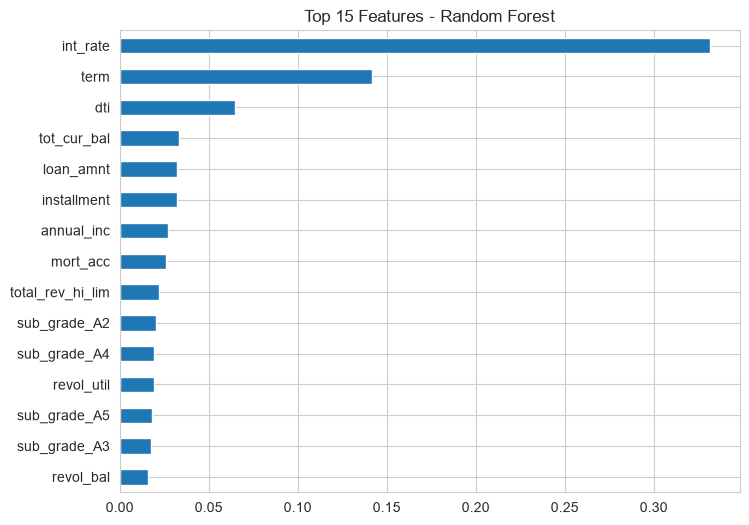

In [93]:
feature_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(8, 6),
    title="Top 15 Features - Random Forest"
)

In [94]:
log_coefficients = pd.Series(
    log_model.coef_[0],
    index=X_train.columns
).sort_values()

log_coefficients

loan_amnt          -0.184299
int_rate           -0.131026
total_rev_hi_lim   -0.097787
tot_cur_bal        -0.097099
total_acc          -0.087336
                      ...   
sub_grade_D1        0.401810
sub_grade_C2        0.410712
sub_grade_C3        0.417226
sub_grade_C5        0.434373
sub_grade_C4        0.438558
Length: 76, dtype: float32